In [172]:
import Pkg
Pkg.add("FiniteDiff")

    Updating `~/.julia/environments/v1.13/Project.toml`
  [6a86dc24] + FiniteDiff v2.33.0
    Manifest No packages added to or removed from `~/.julia/environments/v1.13/Manifest.toml`


In [173]:
using LinearAlgebra, Plots, QuantEcon, ForwardDiff, Parameters, SparseArrays, Arpack, FiniteDiff
include("./codeLibrary.jl")

interpEGM (generic function with 1 method)

In [ ]:
function setup(;
    α = 0.4,
    β = 0.98,
    δ = 0.02,
    γ = 2.0,
    σ = 0.2,
    σ_z = 1.0 ,
    ρ = 0.95,
    lamw = 0.6,
    Lbar = 1.0,
    a_min = 0.0,
    a_max = 250.0,
    Penalty = 1e10,
    N_a = 201,
    N_d = 501,
    N_s = 2,
    endow = [1.0;2.5])
    a = collect(range(0.0,a_max,N_a))
    grids_asset = a_min .+ (a_max - a_min) .* (a./a_max).^4.0
    a_d = collect(range(0.0,a_max,N_d))
    dist_asset = a_min .+ (a_max - a_min) .* (a_d./a_max).^4.0
    trans_emp = [1.0 - lamw σ; lamw 1.0 - σ]
    dist = eigen(trans_emp)
    mini = argmin(abs.(dist.values .- 1.0))
    inv_dist = dist.vectors[:,mini] ./ sum(dist.vectors[:,mini])
    emp = endow ./ dot(inv_dist,endow)
    grids_l = repeat(grids_asset,2)
    
    return (α = α, β = β, δ = δ, γ = γ, σ = σ, Lbar = Lbar, a_min = a_min,
            a_max = a_max, Penalty = Penalty, endow = endow, grids_asset = grids_asset,
            grids_l = grids_l, dist_asset = dist_asset, trans_emp = trans_emp,
            inv_dist = inv_dist, emp = emp, N_a = N_a, N_s = N_s, N_d = N_d, ρ = ρ, σ_z = σ_z)
end

function solve_price(K,Z,params)
    @unpack α, Lbar, δ = params
    R = Z*α*K^(α-1.0)*Lbar^(1.0-α)+1.0-δ
    w = (1.0-α)*Z*K^α*Lbar^(-α)
    return R,w
end



function Agg(K,Z,params)
    R,w = solve_price(K,Z,params)
    return (R = R, w = w)
end
function Backward_EGM(Va_prime,
                      Agg,
                      params)
    @unpack R,w = Agg
    @unpack α, β, γ, trans_emp, emp, grids_asset, N_a, N_s, a_max,a_min = params
    E_Va_prime = Va_prime * trans_emp
    c_endo = (β * E_Va_prime).^(-1.0/γ)
    coh_endo = grids_asset .+ c_endo
    coh = R * grids_asset .+ w * emp'
    pol_a = similar(coh_endo)

    for i_a in 1:N_a
        for i_s in 1:N_s
            m = coh[i_a,i_s]
            if m <= coh_endo[1,i_s]
                pol_a[i_a,i_s] = a_min
            else
                ap = interpEGM(coh_endo[:,i_s],grids_asset,m)[1]
                pol_a[i_a,i_s] = clamp(ap,a_min,a_max)
            end

        end
        
    end
    pol_c = coh .- pol_a
    Va = R * pol_c.^(-γ)
    return Va, pol_a, pol_c
end

function solveEGM(Va_init,
                      Agg_init,
                      params;
                      maxit = 5000,
                      tol = 1e-8)
    crit = 10.0
    @unpack N_a, N_s = params
    Va_prime = copy(Va_init)
    Va = zeros(N_a,N_s)
    pol_a = similar(Va)
    pol_c = similar(Va)
    for t = 1:maxit
        Va, pol_a, pol_c = Backward_EGM(Va_prime,Agg_init,params)
        crit = maximum(abs.(Va .- Va_prime))
        if crit<tol
            break
        end
        Va_prime = Va 
    end
    return Va, pol_a, pol_c
end

function build_transEGM(pol_a,params)
    @unpack N_a, N_s, N_d, dist_asset, a_min, a_max, trans_emp, grids_asset = params
    
    pol_a_fine = similar(pol_a, N_d, N_s)

    for i_s in 1:N_s
        for i_a in 1:N_d
            pol_a_fine[i_a,i_s] = interpEGM(grids_asset,pol_a[:,i_s],dist_asset[i_a])[1]
        end
    end

    I = Int[]
    J = Int[]
    #V = Float64[]
    T = eltype(pol_a)
    V = T[]
    for i_s in 1:N_s
        for i_a in 1:N_d
            ap = pol_a_fine[i_a,i_s]
            col = (i_s - 1)*N_d +i_a
            j = clamp(searchsortedlast(dist_asset,ap),1,N_d -1)
            ω = clamp((ap - dist_asset[j])/(dist_asset[j+1]-dist_asset[j]),0.0,1.0)
            for i_sp in 1:N_s
                p = trans_emp[i_sp,i_s]
                rowL = (i_sp - 1)*N_d + j 
                rowH = rowL+1
                push!(I,rowL)
                push!(J,col)
                push!(V, p * (1.0 - ω))

                push!(I,rowH)
                push!(J,col)
                push!(V, p * ω)
            end
        end
    end
    Q = sparse(I,J,V,N_d*N_s,N_d*N_s)
    return Q , pol_a_fine
end

function stationary_distribution(Q, params;
                                 tol = 1e-12,
                                 maxit = 100_000)

    @unpack N_d, N_s, inv_dist = params

    # 初值：收入边际分布已经处于稳态，
    # 每个收入状态内部先均匀放在资产网格上
    D = zeros(eltype(Q), N_d * N_s)

    for s in 1:N_s
        idx = (s-1)*N_d + 1 : s*N_d
        D[idx] .= inv_dist[s] / N_d
    end

    Dnew = similar(D)

    for it in 1:maxit

        mul!(Dnew, Q, D)

        # 防止累计舍入误差
        Dnew ./= sum(Dnew)

        err = maximum(abs.(Dnew .- D))

        if err < tol
            return copy(Dnew)
        end

        D, Dnew = Dnew, D
    end

    error("Stationary distribution did not converge.")
end
    
function solve_model(K_init, Z_init, params)
    @unpack dist_asset , N_s, γ = params
R_init, w_init = solve_price(K_init, Z_init, params)
coh = R_init*params.grids_asset .+ w_init*params.emp'
c_guess = 0.5 * coh 
uPrime = c -> c.^(-params.γ)
Va_init = R_init * uPrime.(c_guess)
Agg_init = Agg(K_init, Z_init, params)
Va, pol_a, pol_c = solveEGM(Va_init,
                      Agg_init,
                      params;
                      maxit = 5000,
                      tol = 1e-6)
Q, pol_a_fine = build_transEGM(pol_a,params)
vals, vecs = eigs(
    Q;
    nev = 1,
    which = :LM,
    tol = 1e-12,
    maxiter = 10000
)

inv_Q = real(vecs[:,1])
if sum(inv_Q) < 0
    inv_Q .*= -1
end
inv_Q = inv_Q./ sum(inv_Q)
#inv_Q =
#    stationary_distribution(
#        Q,
#        params;
#        tol = 1e-12
#    )
K_s = dot(inv_Q , repeat(dist_asset,N_s))
R,w = Agg(K_s, Z_init,params)
return K_s, Va, pol_a, pol_c, pol_a_fine, inv_Q, R, w
end

solve_model (generic function with 1 method)

In [157]:
params = setup()


(α = 0.4, β = 0.98, δ = 0.02, γ = 2.0, σ = 0.2, Lbar = 1.0, a_min = 0.0, a_max = 250.0, Penalty = 1.0e10, endow = [1.0, 2.5], grids_asset = [0.0, 1.5625e-7, 2.5e-6, 1.2656249999999998e-5, 4.0e-5, 9.765625000000002e-5, 0.00020249999999999996, 0.00037515625000000016, 0.00064, 0.0010251562499999998  …  207.94740015624996, 212.33663999999996, 216.79500015624998, 221.32320249999998, 225.92197265624998, 230.59203999999997, 235.33413765625, 240.1490025, 245.03737515625, 250.0], grids_l = [0.0, 1.5625e-7, 2.5e-6, 1.2656249999999998e-5, 4.0e-5, 9.765625000000002e-5, 0.00020249999999999996, 0.00037515625000000016, 0.00064, 0.0010251562499999998  …  207.94740015624996, 212.33663999999996, 216.79500015624998, 221.32320249999998, 225.92197265624998, 230.59203999999997, 235.33413765625, 240.1490025, 245.03737515625, 250.0], dist_asset = [0.0, 4.000000000000001e-9, 6.400000000000002e-8, 3.2400000000000004e-7, 1.0240000000000003e-6, 2.5e-6, 5.184000000000001e-6, 9.604000000000002e-6, 1.638400000000000

In [ ]:
obj_model = x -> solve_model(x, 1, params)[1] - x
K_sol = bisect(obj_model,1.0,50.0)
K_s, Va, pol_a, pol_c, pol_a_fine, inv_Q, R, w = solve_model(K_sol, 1, params)

In [151]:
function EulerResidualEGM(
    Va::AbstractArray,
    Va_P::AbstractArray,
    Aggs,
    params
)

    @unpack N_a, N_s = params

    Va_mat =
        reshape(
            Va,
            N_a,
            N_s
        )

    Va_P_mat =
        reshape(
            Va_P,
            N_a,
            N_s
        )

    Va_implied,
    pol_a,
    pol_c =
        Backward_EGM(
            Va_P_mat,
            Aggs,
            params
        )

    # scale-free residual
    res =
        Va_mat ./ Va_implied .- 1.0

    return res, pol_a, pol_c 
end

EulerResidualEGM (generic function with 1 method)

In [162]:
function ForwardIteration(D_l,pol_a, params)
    Q, pol_a_fine = build_transEGM(pol_a,params)
    D = Q * D_l
    return D, pol_a_fine
end

function DistResidualEGM(
    pol_a,
    D_L,
    D,
    params
)

    D_imp,
    pol_a_fine =
        ForwardIteration(
            D_L,
            pol_a,
            params
        )

    res =
        (D .- D_imp)[2:end]

    return res, pol_a_fine
end

function AggResidualEGM(
    D,
    K,
    Z_L,
    Z,
    shocks,
    params
)

    @unpack dist_asset,
            N_s,
            ρ,
            σ_z =
        params

    asset_vector =
        repeat(
            dist_asset,
            N_s
        )

    AggAssets =
        dot(
            D,
            asset_vector
        )

    ϵz =
        shocks[1]

    return [
        AggAssets - K;
        log(Z) - ρ*log(Z_L) - σ_z*ϵz
    ]
end

AggResidualEGM (generic function with 1 method)

In [198]:
function F_sys(X_P, X, X_L, shocks, params)
     @unpack N_a, N_s, N_d = params

    m = N_a*N_s

    md = N_d*N_s


    # --------------------------------------------------------
    # split X_{t-1}
    # --------------------------------------------------------

    Va_L = X_L[1:m]

    D_L_red = X_L[m+1:m+md-1]

    K_L, Z_L = X_L[m+md:end]


    # --------------------------------------------------------
    # split X_t
    # --------------------------------------------------------

    Va = X[1:m]

    D_red = X[m+1:m+md-1]

    K, Z = X[m+md:end]


    # --------------------------------------------------------
    # split X_{t+1}
    # --------------------------------------------------------

    Va_P = X_P[1:m]

    D_P_red = X_P[m+1:m+md-1]

    K_P, Z_P = X_P[m+md:end]


    # --------------------------------------------------------
    # reconstruct full distributions
    # --------------------------------------------------------

    D_L =
        vcat(1.0-sum(D_L_red), D_L_red)

    D =
        vcat(1.0-sum(D_red), D_red)


    # --------------------------------------------------------
    # current prices
    #
    # K_{t-1} is predetermined capital
    # --------------------------------------------------------

    Aggs =
        Agg(
            K_L,
            Z,
            params
        )


    # --------------------------------------------------------
    # Euler block
    # --------------------------------------------------------

    euler_root,
    pol_a,
    pol_c =
        EulerResidualEGM(
            Va,
            Va_P,
            Aggs,
            params
        )


    # --------------------------------------------------------
    # Distribution block
    # --------------------------------------------------------

    dist_root,
    pol_a_fine =
        DistResidualEGM(
            pol_a,
            D_L,
            D,
            params
        )


    # --------------------------------------------------------
    # Aggregate block
    # --------------------------------------------------------

    agg_root =
        AggResidualEGM(
            D,
            K,
            Z_L,
            Z,
            shocks,
            params
        )


    return vcat(
        vec(euler_root),
        dist_root,
        agg_root
    )
end

F_sys (generic function with 1 method)

In [160]:
Xss = vcat(vec(Va),inv_Q[2:end],K_s,1.0)
Fss = F_sys(Xss, Xss, Xss, [0.0], params)


1405-element Vector{Float64}:
 -1.5486834037403696e-11
 -1.548661199279877e-11
 -1.5486723015101234e-11
 -1.548650097049631e-11
 -1.548572381437907e-11
 -1.5485501769774146e-11
 -1.5484058479842133e-11
 -1.5482282123002733e-11
 -1.5478507364719007e-11
 -1.5474288517225432e-11
  ⋮
 -4.497378843391697e-11
 -3.59690128087606e-11
 -2.7135802819803573e-11
 -1.95014721868934e-11
 -1.1940989320408186e-11
 -6.045391072264233e-12
 -1.7066301074069916e-12
  0.0
  0.0

In [ ]:
A = FiniteDiff.finite_difference_jacobian(t -> F_sys(t, Xss, Xss, [0.0], params),Xss,Val(:central))
B = FiniteDiff.finite_difference_jacobian(t -> F_sys(Xss, t, Xss,[0.0], params), Xss,Val(:central))
C = FiniteDiff.finite_difference_jacobian(t -> F_sys(Xss, Xss,t,[0.0], params), Xss, Val(:central))
D = FiniteDiff.finite_difference_jacobian(t -> F_sys(Xss, Xss, Xss, t, params), [0.0], Val(:central))
P, Q = LinearTimeIiteration(A, B, C, D)


1405×1 Matrix{Float64}:
  0.0
  0.0
  0.0
  0.0
  0.0
  0.0
  0.0
  0.0
  0.0
  0.0
  ⋮
  0.0
  0.0
  0.0
  0.0
  0.0
  0.0
  0.0
  0.0
 -1.0

In [ ]:
G = Matrix(I,size(P))
X_sim,_ = simulate(LSS(P,Q,G),200)

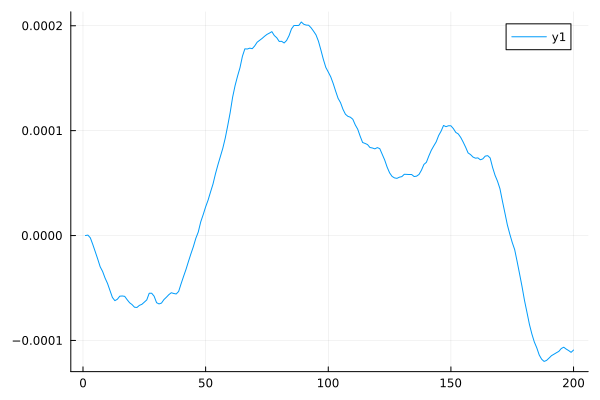

In [205]:
plot(X_sim[1402,:])

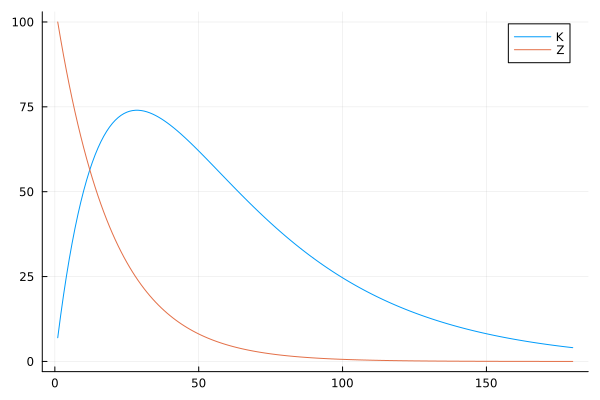

In [203]:
Irf_X = zeros(size(P,1),180)
Irf_X[:,1] = Q
for t = 2:180
    Irf_X[:,t] = P*Irf_X[:,t-1]
end
plot(
    100 .* Irf_X[end-1,:] ./ Xss[end-1],
    label = "K"
)

plot!(
    100 .* Irf_X[end,:] ./ Xss[end],
    label = "Z"
)